# Predicting MEDV Housing Price

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42 

df = pd.read_csv("boston_r.csv")
print(f"Shape: {df.shape[0]} rows x {df.shape[1]} columns")
df.head()

Shape: 506 rows x 14 columns


,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,black,lstat,medv
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2


## (a) EDA and correlation heatmap

In [8]:
print(int(df.isna().sum().sum()))
print(int(df.duplicated().sum()))
df.describe().T.round(3)

0
0


,count,mean,std,min,25%,50%,75%,max
crim,506.0,3.614,8.602,0.006,0.082,0.257,3.677,88.976
zn,506.0,11.364,23.322,0.000,0.000,0.000,12.500,100.000
indus,506.0,11.137,6.860,0.460,5.190,9.690,18.100,27.740
chas,506.0,0.069,0.254,0.000,0.000,0.000,0.000,1.000
nox,506.0,0.555,0.116,0.385,0.449,0.538,0.624,0.871
rm,506.0,6.285,0.703,3.561,5.885,6.208,6.624,8.780
age,506.0,68.575,28.149,2.900,45.025,77.500,94.075,100.000
dis,506.0,3.795,2.106,1.130,2.100,3.207,5.188,12.126
rad,506.0,9.549,8.707,1.000,4.000,5.000,24.000,24.000
tax,506.0,408.237,168.537,187.000,279.000,330.000,666.000,711.000


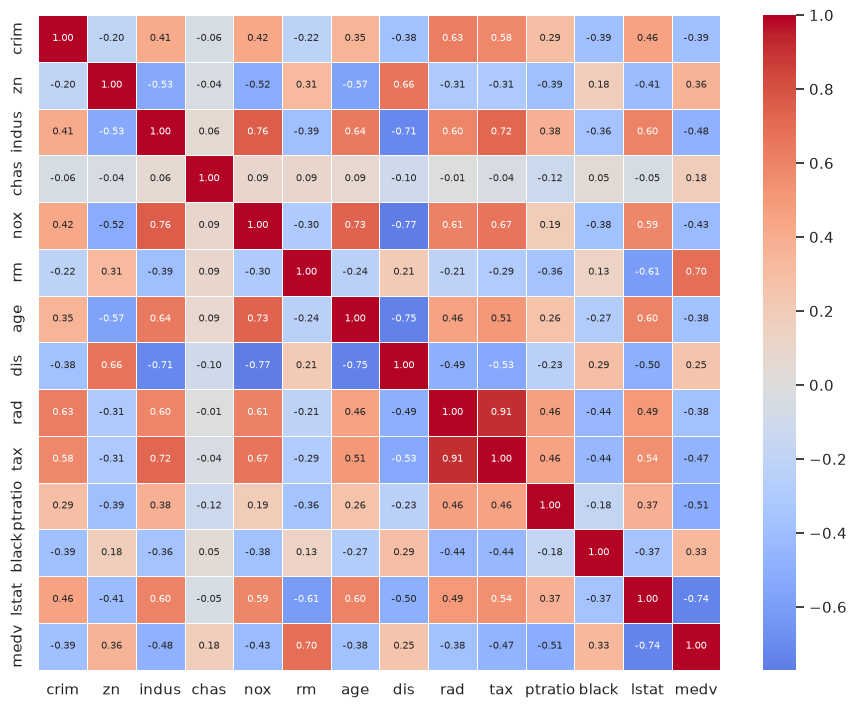

In [9]:
corr = df.corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(11, 8.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            linewidths=0.5, annot_kws={"size": 7}, ax=ax)
plt.show()

In [12]:
corr_medv = corr["medv"].sort_values(key=abs, ascending=False)
print(corr_medv)

medv       1.000000
lstat     -0.737663
rm         0.695360
ptratio   -0.507787
indus     -0.483725
tax       -0.468536
nox       -0.427321
crim      -0.388305
rad       -0.381626
age       -0.376955
zn         0.360445
black      0.333461
dis        0.249929
chas       0.175260
Name: medv, dtype: float64


Answer: lstat and rm
## (c) Linear regression on lstat and rm

In [15]:
X = df[top2]
y = df["medv"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE)

scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

model = LinearRegression().fit(X_train_s, y_train)

In [16]:
y_pred = model.predict(X_test_s)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
print(f"RMSE: {rmse} ")
print(f"R^2 : {r2_score(y_test, y_pred)}")

RMSE: 5.589569804715174 
R^2 : 0.5739577415025859


## Equation

In [17]:
# Regression equation on the standardised features (what the model actually fitted):
b0, (b1, b2) = model.intercept_, model.coef_
print(f"medv = {b0:.4f} + ({b1:.4f}) * z_lstat + ({b2:.4f}) * z_rm")

medv = 22.7965 + (-4.4917) * z_lstat + (3.8724) * z_rm


### RMSE

Test RMSE = 5.5896 (*1000), with R² = 0.5740.

So the model's predictions are off by about 5,590 on average